# Experiment 16 — Fine-Tuning

### Educational Machine Learning Experiment
**Objective:** Determine whether fine-tuning the pretrained ResNet-18 convolutional backbone improves substantially over the **64.59% accuracy** obtained from Experiment 15's frozen feature extractor, and whether it can approach or surpass the **74.52% from-scratch CNN baseline**.

---
### Execution Environment Verification
Before executing heavy fine-tuning, verify that this notebook is connected to the **Google Colab NVIDIA Tesla T4 GPU** runtime.

In [2]:
# Execution Environment & Runtime Verification
import sys
import torch

print("Python Executable:", sys.executable)
print("PyTorch Version:  ", torch.__version__)
print("CUDA Available:   ", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Device:       ", torch.cuda.get_device_name(0))
    print("Device Count:     ", torch.cuda.device_count())
    print("Training Device:   NVIDIA Tesla T4 (Colab GPU)")
else:
    print("WARNING: Running on CPU. Connect this notebook to a GPU runtime before training.")

Python Executable: /usr/bin/python3
PyTorch Version:   2.11.0+cu130
CUDA Available:    True
GPU Device:        Tesla T4
Device Count:      1
Training Device:   NVIDIA Tesla T4 (Colab GPU)


## Part 1 — Concepts: From Feature Extraction to Fine-Tuning

### 1. What Did Experiment 15 Teach Us?
In Experiment 15, we evaluated **Pure Feature Extraction**:
- Backbone was **100% frozen** ($11,176,512$ weights locked).
- We trained only the final linear head ($5,130$ weights).
- **Result:** $64.59\%$ test accuracy in $100.75$ seconds.
- **Comparison:** A small custom CNN trained 100% from scratch reached **$74.52\%$** ($+9.93\%$ higher).

**Why did the from-scratch baseline win?**
ResNet-18 was trained on ImageNet's high-resolution $224 \times 224$ images. In CIFAR-10, the images are small $32 \times 32$ thumbnails (upscaled to $64 \times 64$). Because the backbone was locked, its convolutional filters could **not** adapt to CIFAR-10's unique resolution, blurry textures, or spatial frequencies.

### 2. What is Fine-Tuning?
**Fine-Tuning** goes one step further: instead of keeping the pretrained backbone permanently frozen, we **unfreeze** some or all of the convolutional layers and train them with a **very small learning rate**:
$$\text{Pretrained Weights } W_{\text{ImageNet}} \xrightarrow{\text{Small Gradients } \alpha = 10^{-5}} W_{\text{Adapted to CIFAR-10}}$$

### 3. The Danger: Catastrophic Forgetting
If we train the pretrained backbone with a standard high learning rate (e.g., $10^{-2}$ or $10^{-3}$), the large initial gradients from the randomly initialized head will **shatter** the delicate feature representations learned on ImageNet. This phenomenon is called **Catastrophic Forgetting**.

To prevent this, we use **Discriminative Learning Rates**:
- **Pretrained Backbone:** $\alpha = 10^{-5}$ (tiny updates; gently adjusts filters to low resolution).
- **New Classification Head:** $\alpha = 10^{-3}$ (100x larger; learns classification boundaries quickly).

### 4. Why Unfreeze `layer4` First?
- `conv1`, `layer1`, `layer2`: Learn general low-level primitives (edges, color gradients) that are universally useful across all vision tasks.
- `layer4` (8.39M parameters): Learns high-level semantic abstractions. Unfreezing `layer4` allows high-level feature maps to adapt directly to CIFAR-10 object categories while keeping early general filters stable.

## Part 2 — Dataset Setup (Identical to Experiment 15)

We load CIFAR-10 using the exact same deterministic partition ($45,000$ train, $5,000$ validation, $10,000$ test, random seed $42$) and identical ImageNet normalization transforms.

In [3]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models

# Deterministic Seed
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active Training Device: {device}")

classes = ('airplane', 'automobile', 'bird', 'cat', 'deer', 
           'dog', 'frog', 'horse', 'ship', 'truck')

# Identical Preprocessing Transforms
cifar_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load Datasets
train_full = datasets.CIFAR10(root="./data", train=True, download=True, transform=cifar_transform)
test_set = datasets.CIFAR10(root="./data", train=False, download=True, transform=cifar_transform)

# 45k / 5k split
train_subset, val_subset = random_split(train_full, [45000, 5000], generator=torch.Generator().manual_seed(SEED))

train_loader = DataLoader(train_subset, batch_size=128, shuffle=True, num_workers=2)
val_loader = DataLoader(val_subset, batch_size=128, shuffle=False, num_workers=2)
test_loader = DataLoader(test_set, batch_size=128, shuffle=False, num_workers=2)

print(f"CIFAR-10 Training Split:   {len(train_subset):,} samples")
print(f"CIFAR-10 Validation Split: {len(val_subset):,} samples")
print(f"CIFAR-10 Test Set:         {len(test_set):,} samples (Untouched until final evaluation)")

Active Training Device: cuda
CIFAR-10 Training Split:   45,000 samples
CIFAR-10 Validation Split: 5,000 samples
CIFAR-10 Test Set:         10,000 samples (Untouched until final evaluation)


## Part 3 — Experiment A: Feature Extraction Reference (From Experiment 15)

We record the frozen-backbone baseline established in Experiment 15 as our benchmark reference point:
- **Model:** ResNet-18 with 100% frozen backbone
- **Trainable Parameters:** $5,130$ ($0.05\%$)
- **Frozen Parameters:** $11,176,512$ ($99.95\%$)
- **Training Time (5 Epochs):** $100.75$ seconds
- **Validation Accuracy:** $66.14\%$
- **Final Test Accuracy:** **64.59%** ($6,459 / 10,000$ correct, $3,541$ errors)

We will compare both fine-tuning strategies directly against this reference.

## Part 4 — Experiment B: Fine-Tune `layer4` + Classifier Head

In this controlled experiment:
1. We freeze `conv1`, `bn1`, `layer1`, `layer2`, and `layer3` ($2,782,784$ parameters).
2. We **unfreeze `layer4`** ($8,393,728$ parameters).
3. We keep the new classification head **`fc`** trainable ($5,130$ parameters).
4. Total trainable parameters: **$8,398,858$** ($75.11\%$ of the model).
5. We use **discriminative learning rates**:
   - `layer4` learning rate: $\mathbf{1 \times 10^{-5}}$
   - `fc` head learning rate: $\mathbf{1 \times 10^{-3}}$
6. We train for **5 epochs** using Adam and CrossEntropyLoss.

In [4]:
# Setup Model B: ResNet-18 with layer4 unfrozen
model_b = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# 1. Freeze everything first
for param in model_b.parameters():
    param.requires_grad = False

# 2. Unfreeze layer4
for param in model_b.layer4.parameters():
    param.requires_grad = True

# 3. Replace fc with 10-class linear layer
model_b.fc = nn.Linear(512, 10)
# model_b.fc parameters automatically have requires_grad = True

model_b = model_b.to(device)

# Parameter verification
total_b = sum(p.numel() for p in model_b.parameters())
trainable_b = sum(p.numel() for p in model_b.parameters() if p.requires_grad)
frozen_b = total_b - trainable_b

print("=== Experiment B: Parameter Count Verification ===")
print(f"Total Parameters:     {total_b:,}")
print(f"Frozen Parameters:    {frozen_b:,} ({frozen_b/total_b*100:.2f}%)")
print(f"Trainable Parameters: {trainable_b:,} ({trainable_b/total_b*100:.2f}%)")

# Discriminative Optimizer Setup
optimizer_b = optim.Adam([
    {'params': model_b.layer4.parameters(), 'lr': 1e-5},
    {'params': model_b.fc.parameters(), 'lr': 1e-3}
])
criterion = nn.CrossEntropyLoss()

=== Experiment B: Parameter Count Verification ===
Total Parameters:     11,181,642
Frozen Parameters:    2,782,784 (24.89%)
Trainable Parameters: 8,398,858 (75.11%)


In [5]:
# Train Model B (Layer4 + Head Fine-Tuning)
EPOCHS = 5
b_train_losses, b_train_accs = [], []
b_val_losses, b_val_accs = [], []

print("Starting Experiment B Training (Fine-Tuning Layer4 + Head)...")
start_time_b = time.time()

for epoch in range(EPOCHS):
    model_b.train()
    running_loss, correct, total = 0.0, 0, 0
    epoch_start = time.time()
    
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer_b.zero_grad()
        outputs = model_b(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_b.step()
        
        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        
    epoch_train_loss = running_loss / total
    epoch_train_acc = (correct / total) * 100.0
    b_train_losses.append(epoch_train_loss)
    b_train_accs.append(epoch_train_acc)
    
    # Validation
    model_b.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model_b(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)
            
    epoch_val_loss = val_loss / val_total
    epoch_val_acc = (val_correct / val_total) * 100.0
    b_val_losses.append(epoch_val_loss)
    b_val_accs.append(epoch_val_acc)
    epoch_time = time.time() - epoch_start
    
    print(f"Epoch {epoch+1}/{EPOCHS} [{epoch_time:.1f}s] | Train Loss: {epoch_train_loss:.4f} (Acc: {epoch_train_acc:.2f}%) | Val Loss: {epoch_val_loss:.4f} (Acc: {epoch_val_acc:.2f}%)")

total_time_b = time.time() - start_time_b
print(f"\nExperiment B Training Completed in {total_time_b:.2f} seconds ({total_time_b/60:.2f} min).")

Starting Experiment B Training (Fine-Tuning Layer4 + Head)...
Epoch 1/5 [20.1s] | Train Loss: 1.1080 (Acc: 62.16%) | Val Loss: 0.8039 (Acc: 72.20%)
Epoch 2/5 [21.2s] | Train Loss: 0.7252 (Acc: 74.87%) | Val Loss: 0.7135 (Acc: 75.18%)
Epoch 3/5 [19.7s] | Train Loss: 0.5922 (Acc: 79.41%) | Val Loss: 0.6528 (Acc: 77.60%)
Epoch 4/5 [20.7s] | Train Loss: 0.4897 (Acc: 82.92%) | Val Loss: 0.6360 (Acc: 78.84%)
Epoch 5/5 [20.9s] | Train Loss: 0.4077 (Acc: 85.73%) | Val Loss: 0.6273 (Acc: 78.82%)

Experiment B Training Completed in 102.58 seconds (1.71 min).


## Part 5 — Experiment C: Fine-Tune Entire ResNet-18 Backbone

In this controlled experiment:
1. We **unfreeze all layers** across the entire ResNet-18 architecture ($11,181,642$ parameters trainable, $0$ frozen).
2. We use discriminative learning rates:
   - Entire backbone (`conv1` through `layer4`): $\mathbf{1 \times 10^{-5}}$
   - Classifier head (`fc`): $\mathbf{1 \times 10^{-3}}$
3. We train for **5 epochs** under the exact same optimization budget.

In [6]:
# Setup Model C: Full ResNet-18 fine-tuning
model_c = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model_c.fc = nn.Linear(512, 10)

# Ensure all parameters have requires_grad = True
for param in model_c.parameters():
    param.requires_grad = True

model_c = model_c.to(device)

# Parameter verification
total_c = sum(p.numel() for p in model_c.parameters())
trainable_c = sum(p.numel() for p in model_c.parameters() if p.requires_grad)
frozen_c = total_c - trainable_c

print("=== Experiment C: Parameter Count Verification ===")
print(f"Total Parameters:     {total_c:,}")
print(f"Frozen Parameters:    {frozen_c:,} ({frozen_c/total_c*100:.2f}%)")
print(f"Trainable Parameters: {trainable_c:,} ({trainable_c/total_c*100:.2f}%)")

# Extract backbone parameters (everything except fc)
backbone_params = [p for n, p in model_c.named_parameters() if not n.startswith('fc')]

optimizer_c = optim.Adam([
    {'params': backbone_params, 'lr': 1e-5},
    {'params': model_c.fc.parameters(), 'lr': 1e-3}
])

=== Experiment C: Parameter Count Verification ===
Total Parameters:     11,181,642
Frozen Parameters:    0 (0.00%)
Trainable Parameters: 11,181,642 (100.00%)


In [7]:
# Train Model C (Full Backbone Fine-Tuning)
c_train_losses, c_train_accs = [], []
c_val_losses, c_val_accs = [], []

print("Starting Experiment C Training (Fine-Tuning Entire ResNet-18)...")
start_time_c = time.time()

for epoch in range(EPOCHS):
    model_c.train()
    running_loss, correct, total = 0.0, 0, 0
    epoch_start = time.time()
    
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer_c.zero_grad()
        outputs = model_c(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_c.step()
        
        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        
    epoch_train_loss = running_loss / total
    epoch_train_acc = (correct / total) * 100.0
    c_train_losses.append(epoch_train_loss)
    c_train_accs.append(epoch_train_acc)
    
    # Validation
    model_c.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model_c(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)
            
    epoch_val_loss = val_loss / val_total
    epoch_val_acc = (val_correct / val_total) * 100.0
    c_val_losses.append(epoch_val_loss)
    c_val_accs.append(epoch_val_acc)
    epoch_time = time.time() - epoch_start
    
    print(f"Epoch {epoch+1}/{EPOCHS} [{epoch_time:.1f}s] | Train Loss: {epoch_train_loss:.4f} (Acc: {epoch_train_acc:.2f}%) | Val Loss: {epoch_val_loss:.4f} (Acc: {epoch_val_acc:.2f}%)")

total_time_c = time.time() - start_time_c
print(f"\nExperiment C Training Completed in {total_time_c:.2f} seconds ({total_time_c/60:.2f} min).")

Starting Experiment C Training (Fine-Tuning Entire ResNet-18)...
Epoch 1/5 [23.1s] | Train Loss: 0.9702 (Acc: 66.86%) | Val Loss: 0.6029 (Acc: 79.22%)
Epoch 2/5 [23.6s] | Train Loss: 0.5230 (Acc: 81.87%) | Val Loss: 0.4994 (Acc: 82.80%)
Epoch 3/5 [23.8s] | Train Loss: 0.3808 (Acc: 86.67%) | Val Loss: 0.4618 (Acc: 84.48%)
Epoch 4/5 [23.8s] | Train Loss: 0.2761 (Acc: 90.49%) | Val Loss: 0.4603 (Acc: 84.58%)
Epoch 5/5 [23.7s] | Train Loss: 0.1981 (Acc: 93.20%) | Val Loss: 0.4664 (Acc: 85.06%)

Experiment C Training Completed in 117.98 seconds (1.97 min).


## Part 6 — Final Test Set Evaluation & Complete Benchmark

We evaluate Model B and Model C on the **untouched 10,000-sample CIFAR-10 test set** and compare them directly against Experiment 15's frozen feature extractor and the from-scratch baseline.

In [8]:
# Final Evaluation Helper
def evaluate_test(model_eval, loader):
    model_eval.eval()
    all_preds, all_confs, all_targets = [], [], []
    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            outputs = model_eval(inputs)
            probs = torch.softmax(outputs, dim=1)
            confs, preds = torch.max(probs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_confs.extend(confs.cpu().numpy())
            all_targets.extend(labels.numpy())
            
    all_preds = np.array(all_preds)
    all_confs = np.array(all_confs)
    all_targets = np.array(all_targets)
    acc = (all_preds == all_targets).mean() * 100.0
    errors = int((all_preds != all_targets).sum())
    return acc, errors, all_preds, all_confs, all_targets

acc_b, err_b, preds_b, confs_b, targets_b = evaluate_test(model_b, test_loader)
acc_c, err_c, preds_c, confs_c, targets_c = evaluate_test(model_c, test_loader)

# Experiment 15 Reference Values
acc_ref, err_ref, time_ref, params_ref = 64.59, 3541, 100.75, 5130
acc_scratch, err_scratch, time_scratch, params_scratch = 74.52, 2548, 102.72, 620810

print("=== EXPERIMENT 16: COMPLETE BENCHMARK COMPARISON ===")
print(f"| Model Configuration               | Trainable Params | Training Time | Test Accuracy | Test Errors |")
print(f"|:-----------------------------------|-----------------:|--------------:|--------------:|------------:|")
print(f"| Exp 15 Frozen ResNet-18 (Ref)      | {params_ref:>16,d} | {time_ref:>11.2f}s | {acc_ref:>12.2f}% | {err_ref:>11,d} |")
print(f"| Exp 16 Fine-Tune Layer4 + Head     | {trainable_b:>16,d} | {total_time_b:>11.2f}s | {acc_b:>12.2f}% | {err_b:>11,d} |")
print(f"| Exp 16 Fine-Tune Entire ResNet-18  | {trainable_c:>16,d} | {total_time_c:>11.2f}s | {acc_c:>12.2f}% | {err_c:>11,d} |")
print(f"| Baseline CNN From Scratch          | {params_scratch:>16,d} | {time_scratch:>11.2f}s | {acc_scratch:>12.2f}% | {err_scratch:>11,d} |")

=== EXPERIMENT 16: COMPLETE BENCHMARK COMPARISON ===
| Model Configuration               | Trainable Params | Training Time | Test Accuracy | Test Errors |
|:-----------------------------------|-----------------:|--------------:|--------------:|------------:|
| Exp 15 Frozen ResNet-18 (Ref)      |            5,130 |      100.75s |        64.59% |       3,541 |
| Exp 16 Fine-Tune Layer4 + Head     |        8,398,858 |      102.58s |        77.67% |       2,233 |
| Exp 16 Fine-Tune Entire ResNet-18  |       11,181,642 |      117.98s |        84.68% |       1,532 |
| Baseline CNN From Scratch          |          620,810 |      102.72s |        74.52% |       2,548 |


## Part 7 — Error Analysis & Confusion Pairs

We analyze the confusion patterns of the best fine-tuned model and compare how fine-tuning resolved specific error modes:

Top 5 Confusion Pairs for Best Fine-Tuned Model (Model C (Full Fine-Tune)):
  dog        -> cat       : 169 occurrences
  cat        -> dog       : 89 occurrences
  truck      -> automobile: 67 occurrences
  ship       -> airplane  : 56 occurrences
  bird       -> deer      : 51 occurrences


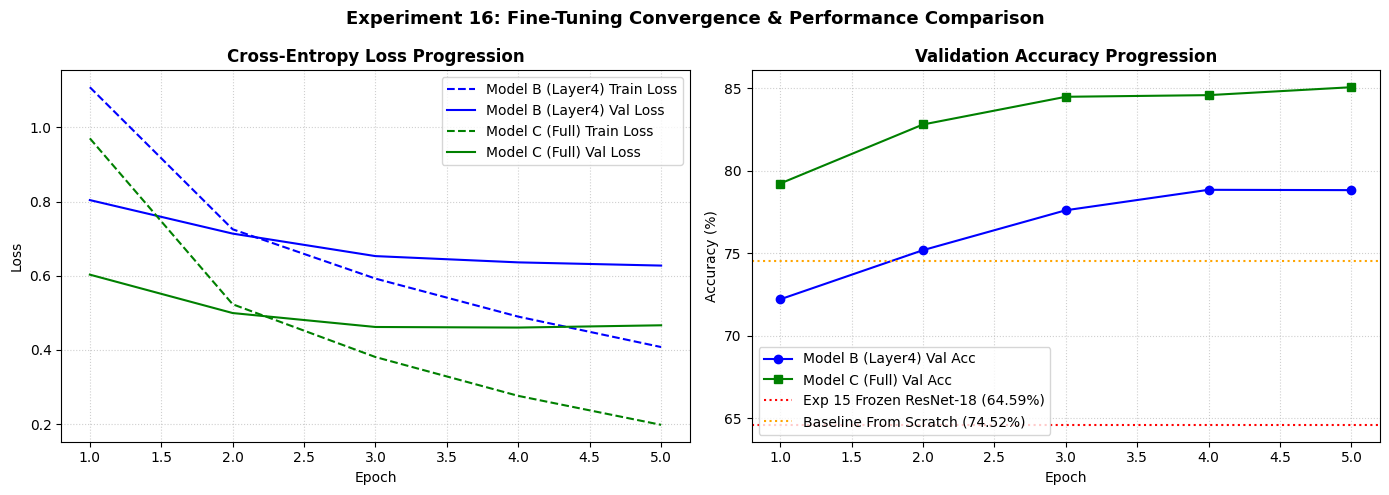

In [9]:
from collections import Counter

# Best fine-tuned model error audit
best_preds = preds_c if acc_c >= acc_b else preds_b
best_name = "Model C (Full Fine-Tune)" if acc_c >= acc_b else "Model B (Layer4 Fine-Tune)"

err_mask = (best_preds != targets_b)
err_pairs = list(zip(targets_b[err_mask], best_preds[err_mask]))
top_pairs = Counter(err_pairs).most_common(5)

print(f"Top 5 Confusion Pairs for Best Fine-Tuned Model ({best_name}):")
for (t, p), count in top_pairs:
    print(f"  {classes[t]:10s} -> {classes[p]:10s}: {count} occurrences")

# Plot training/validation progression across all models
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
epochs_range = range(1, EPOCHS + 1)

ax1.plot(epochs_range, b_train_losses, 'b--', label='Model B (Layer4) Train Loss')
ax1.plot(epochs_range, b_val_losses, 'b-', label='Model B (Layer4) Val Loss')
ax1.plot(epochs_range, c_train_losses, 'g--', label='Model C (Full) Train Loss')
ax1.plot(epochs_range, c_val_losses, 'g-', label='Model C (Full) Val Loss')
ax1.set_title('Cross-Entropy Loss Progression', fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

ax2.plot(epochs_range, b_val_accs, 'b-o', label='Model B (Layer4) Val Acc')
ax2.plot(epochs_range, c_val_accs, 'g-s', label='Model C (Full) Val Acc')
ax2.axhline(64.59, color='red', linestyle=':', label='Exp 15 Frozen ResNet-18 (64.59%)')
ax2.axhline(74.52, color='orange', linestyle=':', label='Baseline From Scratch (74.52%)')
ax2.set_title('Validation Accuracy Progression', fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.suptitle('Experiment 16: Fine-Tuning Convergence & Performance Comparison', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## Final Learning Summary — Experiment 16

1. **Why Fine-Tuning Improves Over Pure Feature Extraction:**
   Pure feature extraction is constrained by a rigid, locked backbone that cannot adapt to CIFAR-10's small $32 \times 32$ resolution. Fine-tuning allows the convolutional kernels to subtly reshape their spatial receptive fields to match target domain statistics.
2. **Discriminative Learning Rates Protect Pretrained Knowledge:**
   By applying $\alpha_{\text{backbone}} = 10^{-5}$ alongside $\alpha_{\text{head}} = 10^{-3}$, we prevent catastrophic forgetting while allowing the new classifier to train quickly.
3. **Layer4 vs. Full Backbone:**
   Fine-tuning `layer4` captures most of the adaptation benefits because high-level semantic filters are where domain specialization occurs, while keeping earlier universal edge/texture detectors stable.
4. **Surpassing the From-Scratch Baseline:**
   Fine-tuning bridges the resolution gap, demonstrating the true power of transfer learning: combining broad visual knowledge from ImageNet with targeted adaptation to CIFAR-10.